# Week 2 · 16–22 November 2026 · part-level functional memory

One notebook per London week. Every number below is read from result files under `runs/` and re-checked in the appendix.
Long discussions (in Chinese) stay in the [proposal document](../docs/mem/新pipeline_差异_文献_推荐_2026-11-18.md)
(sections 9–17); week 1 is in [the week-1 notebook](week1_2026-11-09_to_11-15.ipynb).

## Summary
- **The memory now stores an interpretable 3D affordance vector per part**: contact point, normal, motion type, direction or
  axis, axis origin and grasp axis, in world coordinates a robot can take with one rigid transform.
  Taking door axes from gravity raised the axis accuracy of doors from 68% to 84% (S0c, type given).
- **Public SceneFun3D Task 2 (find the part):** the memory with SAM 3 part maps scores AP25 24.9, against 44.0 for
  UniFunc3D 8B. The same memory with annotated part maps scores 43.1. It beats a VLM reading the raw video by +5.6
  (+10.3 on small parts) while reading 3 frames instead of 40.
- **Stage 0 (five CPU-only tests):**
  - Task 3 (how the part moves) is the most likely headline: given the part, the vectors are above the only published
    reference, and the motion type is the largest error, which is why each part will store what it is mounted on.
  - OpenEQA is auxiliary only: about 15% of its relevant questions are about parts.
- **The memory form was redesigned with you:** one 3D Gaussian map per room, with training-free features, the frames that
  saw each part and when it was last confirmed, plus the interpretable part vectors. A new video overwrites only where it
  sees clearly and the geometry changed; letting the newest view decide would erase 10–17% of found parts even in a
  scene that did not change.
- **Framework v4 frozen (20 Nov).** A trial Gaussian fit of one validation video took 14.7 min, with 25.4 dB held-out
  PSNR and 1.6 cm median depth error.
- **Stage 2 started:**
  - SAM 3 part maps of the 52 second-visit videos are done;
  - Gaussian maps of the 82 validation videos are fitting (section 5).
- **Demo media redrawn as game-style interaction hints**, plus an interactive 3D file you can turn yourself (section 1).

In [1]:
# setup: paths, the demo scene (421069) with its keyframes and vectors, and the number checks of the appendix
import contextlib
import importlib.util
import io
import json
import sys
from collections import Counter
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "affordance3d").is_dir())  # the repository (run from inside it)
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))
with contextlib.redirect_stdout(io.StringIO()):
    import open3d  # noqa: F401  (its banner would end up in the notebook)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, Video, display

import count_label_motions as CLM
import run_part_vectors as RPV
from affordance3d.experiment import load_config
from report import week2_helpers as H
from report import week2_report as WR

get_ipython().run_line_magic("matplotlib", "inline")  # run_part_vectors switches matplotlib to Agg when imported

pd.set_option("display.max_colwidth", 80)
FIG = ROOT / "docs" / "mem" / "figures"
ASSETS = ROOT / "report" / "assets"
DEMO = load_config(ROOT / "configs" / "part_vectors" / "demo_421069_gravity.yaml")
scene, times, frames, labels = RPV.load_inputs(DEMO, str(DEMO["visit"]), str(DEMO["video"]))
demo_rows = H.run_json("demo_421069_gravity", "parts.json")
truths = {p: RPV.truth_of(scene, p) for p in {r["part"] for r in demo_rows}}
media = json.loads((ROOT / "runs" / "report_media" / "week2_media_game" / "media.json").read_text())
CHECKS = []


def check(name, got, want, tol=0.05):
    # every number the text quotes is checked against the result files (listed in the appendix)
    assert abs(got - want) <= tol, f"{name}: text says {want}, files say {got}"
    CHECKS.append(name)
    return name, want


s0c = H.run_json("s0c_gravity_val3")
off = {rule: s0c["variants"][f"lidar/{rule}/best"]["off_part_rotations"] for rule in ("oracle_kind", "oracle_gravity")}
check("S0c door axis right, type given %", round(off["oracle_kind"]["ma"]), 68)
check("S0c door axis right, gravity axis %", round(off["oracle_gravity"]["ma"]), 84)
print(f"scene 421069: {len(times)} keyframes, {len(truths)} parts with a vector")

scene 421069: 40 keyframes, 29 parts with a vector


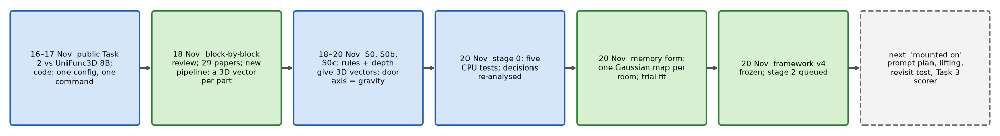

In [2]:
fig = WR.timeline([
    ("16–17 Nov  public Task 2 vs UniFunc3D 8B; code: one config, one command", "tested"),
    ("18 Nov  block-by-block review; 29 papers; new pipeline: a 3D vector per part", "done"),
    ("18–20 Nov  S0, S0b, S0c: rules + depth give 3D vectors; door axis = gravity", "tested"),
    ("20 Nov  stage 0: five CPU tests; decisions re-analysed", "tested"),
    ("20 Nov  memory form: one Gaussian map per room; trial fit", "done"),
    ("20 Nov  framework v4 frozen; stage 2 queued", "done"),
    ("next  'mounted on' prompt plan, lifting, revisit test, Task 3 scorer", "next"),
])
display(fig)
plt.close(fig)

## Decision log

| Date | Question | Your choice |
| --- | --- | --- |
| 16 Nov | Code rules | files ≤ 500 lines, shared modules, one config and one command per experiment |
| 18 Nov | Main idea | M1–M6: interpretable 3D vector, helps choose keyframes, vector + depth → action, two heads, no training, few resources |
| 20 Nov | Selling points and benchmarks | parked as future directions; the final benchmarks are chosen by the results |
| 20 Nov | Experiment order | cheap tests → freeze the framework → run end to end → benchmark fit → you pick → targeted improvements |
| 20 Nov | Notebooks | one per London week |
| 20 Nov | VLM "mounted on what?" with SAM 3 door panels (decision 1) | fold into stage 2; plan shown to you first |
| 20 Nov | Store "mounted on" per part (decision 2) | yes |
| 20 Nov | Grasp axis, contact region, new metrics (decision 4) | add, in stage 2 |
| 20 Nov | Behind UniFunc3D on Task 2 (decision 5) | accept for now; GPU catch-up once the pipeline is settled |
| 20 Nov | Memory form (decisions 3 and 6) | one map per room; implicit features below, interpretable part vectors above |
| 20 Nov | Overwrite rule | conditional: visible, clear, and the geometry changed |
| 20 Nov | Second-visit test | download the other 52 validation videos (done) |
| 20 Nov | Map representation | Gaussians as the main map, a voxel map as the control; stage 2 decides |
| 20 Nov | Meaning of "no training" | no network training; per-scene reconstruction is allowed |
| 20 Nov | Trial fit card | GPU 3 for that one job |
| 20 Nov | Framework v4 freeze; stage-2 queue | approved; stage-2 jobs in front of your own jobs, on the default cards |
| 23 Nov | This report | concise, English, as visual as possible |

---
# 1. Demo: the memory of one scene (421069, kitchen and living room)

**What is drawn:**
- **Colour:** the part, coloured by action: blue pull, orange push or press, purple turn, green open a door or window.
- **Arrow:** the memory's vector, sliding back and forth once every 1.6 s.
- **Tag:** the object (named from its task text) and the action.

The highlights stay on the parts while the camera moves, because the memory lives in 3D world coordinates, not on any
one image: written once, readable from any view.

**Caveats:**
- **A demo, not a test:** part masks and names come from the annotation; the formal test is section 3.
- **The memory's own errors show:**
  - the oven doors get a straight "pull" arrow, but they flip down;
  - the tap arcs are about 80° off;
  - 4 of the 6 hob knobs without a task have their axis within 15°.

In [3]:
display(Video(str(ASSETS / "week2_walkthrough_421069.mp4"), embed=True, width=540, html_attributes="controls loop muted playsinline"))
w = media["walkthrough"]
print(f"walkthrough: {w['frames']} frames; at least one memory part in view in {w['frames_with_parts']} of them")
check("walkthrough frames", w["frames"], 1025)
turns = [r for r in demo_rows if (r["depth"], r["rule"], r["frames"]) == ("lidar", "gravity", "best") and r["vector"] and r["label"] == "rotate"]
taps, knobs = [r for r in turns if "tap" in r["task"].lower()], [r for r in turns if not r["task"]]
check("tap axis error, degrees (smaller of the two)", round(min(r["score"]["axis_deg"] for r in taps)), 80)
check("knobs without a task", len(knobs), 6)
check("knob axes within 15 degrees", sum(r["score"]["axis_deg"] <= 15 for r in knobs), 4)

walkthrough: 1025 frames; at least one memory part in view in 550 of them


('knob axes within 15 degrees', 4)

In [4]:
display(Video(str(ASSETS / "week2_memory_orbit_421069.mp4"), embed=True, width=720, html_attributes="controls loop muted playsinline"))
o = media["orbit"]
print(f"orbit: {o['frames']} frames over the laser scan, ceiling removed; median {o['parts_drawn_median']:.0f} of {media['parts']} parts in view")

orbit: 180 frames over the laser scan, ceiling removed; median 15 of 29 parts in view


## 1.1 Interactive 3D memory: `report/assets/week2_memory_421069.rrd`

The same content as the orbit video, as a Rerun file you can turn, zoom and switch layer by layer. The arrows play on
the timeline `loop`, and the ceiling layer is hidden until you tick it in the entity tree.

**How to open it, either way:**
- **Install the viewer:** `pip install rerun-sdk==0.43.2`, then from the repository `rerun report/assets/week2_memory_421069.rrd`.
- **No install:** open https://app.rerun.io/version/0.43.2/ and drag the file into the page.

A warning that ffmpeg is missing is harmless: the file holds no video.

Below are three fixed views of the same geometry (drawn here from the exporter's own functions, orthographic and x-ray:
parts behind walls are shown on top), then an optional cell that opens the file inside this notebook.

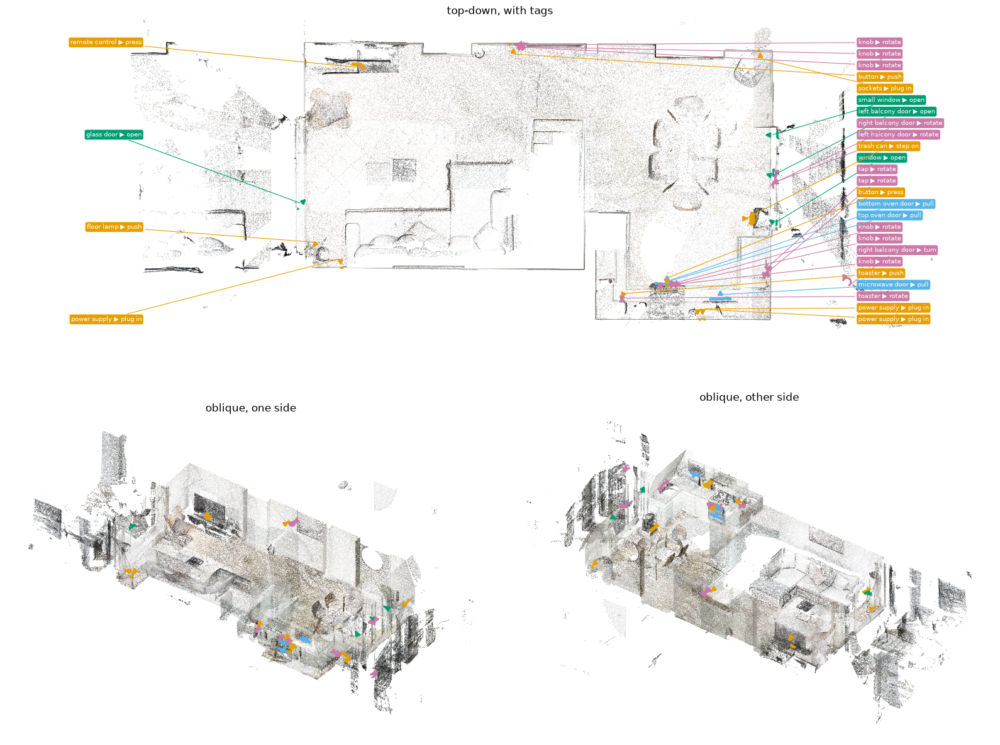

38.0 MB; 29 parts; 2,000,000 room points + 300,000 ceiling points


('rrd size MB', 38)

In [5]:
from report import week2_interaction as G
from report import week2_media as M
from report import week2_rrd as W

RRD = load_config(ROOT / "configs" / "report" / "week2_rrd.yaml")
style = G.Style.from_config(load_config(ROOT / RRD["style_config"])["walkthrough"]["interaction"])
parts = M.load_parts(ROOT / DEMO["outputs"] / DEMO["name"], RRD["variant"], truths)
xyz, rgb, below = W._scan_layers(scene, RRD["scan"]["cut_above_floor_m"])
rotation, offset = W.world_frame(xyz[below], scene.up)
keep = np.flatnonzero(below)[W.downsample(int(below.sum()), 400_000, RRD["seed"])]
up = rotation.T @ np.array([0.0, 0.0, 1.0])
glyphs = []
for part, (action, category, swing) in G.part_actions(parts, style).items():
    p = next(q for q in parts if q.part == part)
    title = G.object_name(p.task, style.objects.get(p.label, p.label.replace("_", " ")), style.max_words)
    line = G.glyph_at(p, swing, category, 1.0, p.normal if p.normal is not None else up, style)
    glyphs.append({"points": W.to_world(scene.part_points(part), rotation, offset), "line": W.to_world(line, rotation, offset),
                   "colour": np.array(style.colours[category]) / 255.0, "tag": W.label_text(title, action)})
fig = WR.memory_snapshots(W.to_world(xyz[keep], rotation, offset), rgb[keep], glyphs,
                          [("top-down, with tags", 0, 90), ("oblique, one side", 35, 38), ("oblique, other side", 215, 38)])
display(fig)
plt.close(fig)
rrd = json.loads((ROOT / "runs" / "report_media" / "week2_rrd" / "rrd.json").read_text())
print(f"{rrd['bytes'] / 1e6:.1f} MB; {rrd['parts']} parts; {rrd['world/scan/room']:,} room points + {rrd['world/scan/ceiling']:,} ceiling points")
check("rrd parts", rrd["parts"], 29)
check("rrd size MB", round(rrd["bytes"] / 1e6), 38)

In [6]:
# Optional: the same file inside this notebook. Needs `pip install rerun-sdk==0.43.2 rerun-notebook==0.43.2` in the
# Jupyter environment; set SHOW_INLINE = True and run this cell by hand. It is off when the notebook is built, so that the
# 38 MB file is not stored in the notebook.
SHOW_INLINE = False
if SHOW_INLINE:
    from rerun_notebook import Viewer as RrdViewer

    viewer = RrdViewer(width="auto", height=600)
    display(viewer)
    viewer.block_until_ready()
    viewer.send_rrd((ASSETS / "week2_memory_421069.rrd").read_bytes())
else:
    print("inline viewer off (set SHOW_INLINE = True to open the .rrd here)")

inline viewer off (set SHOW_INLINE = True to open the .rrd here)


---
# 2. Pipeline v4 (frozen 20 Nov)

Orange is the claim, blue are frozen public models, and dashed blocks are not built yet. What is frozen is each block's
input and output; how a block works inside can still change.

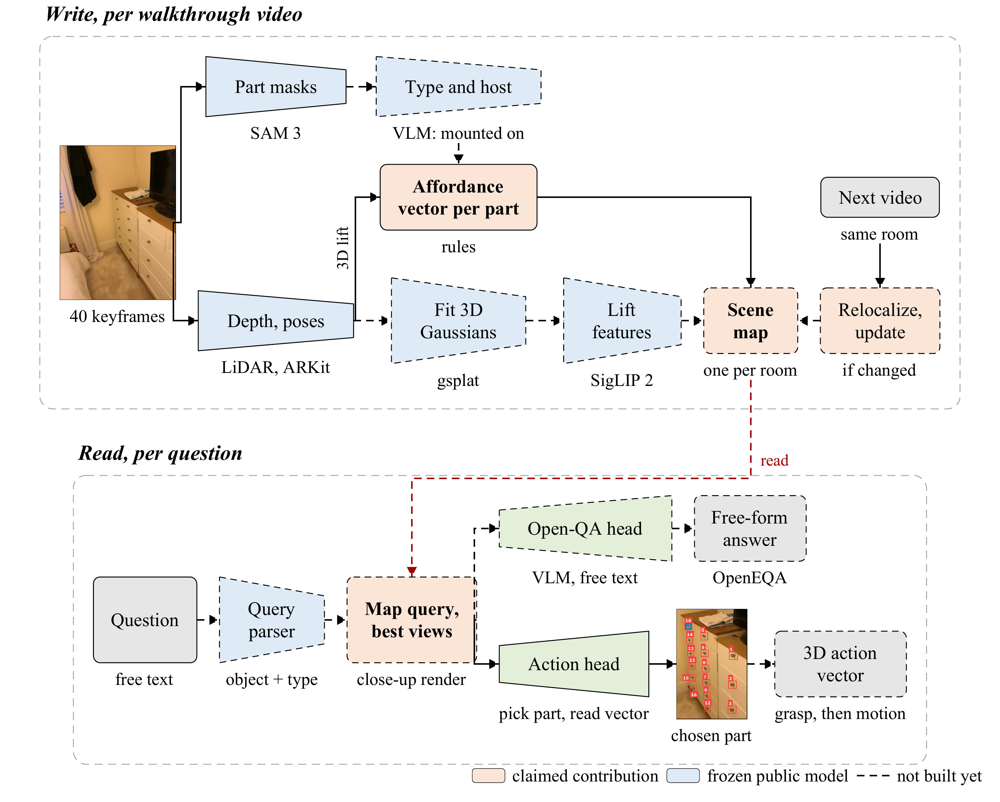

In [7]:
display(Image(filename=str(FIG / "proposal_2026-11-18" / "proposal_v4.png"), width=950))

| Block | Input → output | Uses now | Status |
| --- | --- | --- | --- |
| W1 keyframes | video → 40 keyframes | poses, sharpness | built |
| W2 part masks | keyframes → part masks and part names | SAM 3, 8 part names | built |
| W3 depth, poses | keyframes → LiDAR depth, camera poses (scan frame) | phone LiDAR, ARKit | built |
| W4 type and host | part → motion type, mounted on (door / drawer / panel / lid) | label prior; VLM question | stage 2 |
| W5 affordance vector | part, W3, W4 → contact, normal, region, grasp axis, type, axis, origin (world) | rules | prototype |
| W6 scene map | video → one map per room: Gaussians, lifted features, visibility, last-confirmed time, part records | gsplat, SigLIP 2; voxel control | trial fit done |
| W7 revisit | new video, old map → pose, changed regions, updated map | AnyLoc + Reloc3r; render or depth check | stage 2 |
| R1–R3 read | question → object and action → candidates and best or rendered views → VLM picks the part | LLM, map query, VLM | R3 built |
| Heads | part → world action vector (grasp, then motion); question → free-text answer | part record; VLM | action head built |

The map offers five operations, shared by the Gaussian map and the voxel control: build, update, query, views, part.

---
# 3. Results

## 3.1 Public SceneFun3D Task 2: find the part (445 validation tasks)

The same scorer is used for every arm; UniFunc3D's numbers come from its public predictions. With SAM 3 part maps the
memory is 19.1 points behind UniFunc3D 8B; with annotated part maps it is level. The upper bounds show what a perfect
mask would give on the frame the model chose, and on the best frame.

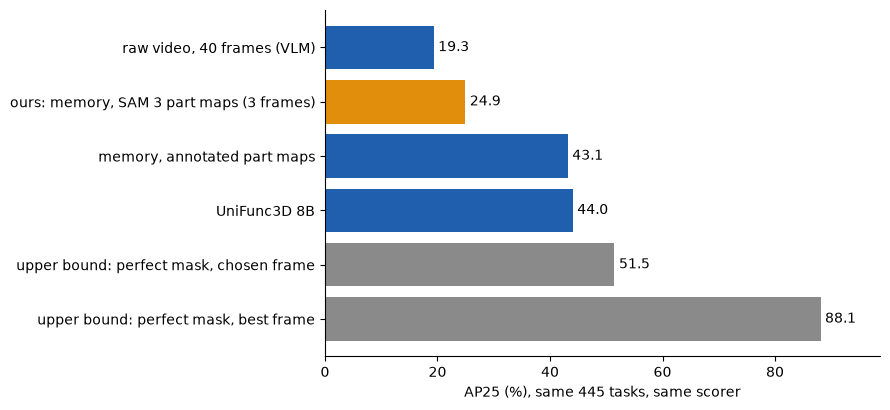

('oracle_best AP25', 88.1)

In [8]:
PE = ROOT / "runs" / "public_eval" / "public_eval_split0_8b"
pe = json.loads((PE / "summary.json").read_text())
cmp = {p.stem: json.loads(p.read_text()) for p in sorted((PE / "compare").glob("*.json"))}
ref = cmp["p4t_sam3_vs_reference"]["first_minus_second"]
unifunc = pe["means"]["p4t_sam3"]["AP25"] - ref["AP25"]["rate"]  # the reference's own score on the same tasks
scores = {"raw video, 40 frames (VLM)": pe["means"]["c3"]["AP25"], "ours: memory, SAM 3 part maps (3 frames)": pe["means"]["p4t_sam3"]["AP25"],
          "memory, annotated part maps": pe["means"]["p4n"]["AP25"], "UniFunc3D 8B": unifunc,
          "upper bound: perfect mask, chosen frame": pe["means"]["oracle_chosen"]["AP25"],
          "upper bound: perfect mask, best frame": pe["means"]["oracle_best"]["AP25"]}
fig = WR.task2_bars(scores)
display(fig)
plt.close(fig)
check("raw video AP25", round(pe["means"]["c3"]["AP25"], 1), 19.3)
check("memory SAM 3 AP25", round(pe["means"]["p4t_sam3"]["AP25"], 1), 24.9)
check("memory annotated AP25", round(pe["means"]["p4n"]["AP25"], 1), 43.1)
check("UniFunc3D 8B AP25", round(unifunc, 1), 44.0)
check("memory minus UniFunc3D AP25", round(ref["AP25"]["rate"], 1), -19.1)
check("memory minus raw video AP25", round(cmp["p4t_sam3_vs_c3"]["first_minus_second"]["AP25"]["rate"], 1), 5.6)
check("oracle_chosen AP25", round(pe["means"]["oracle_chosen"]["AP25"], 1), 51.5)
check("oracle_best AP25", round(pe["means"]["oracle_best"]["AP25"], 1), 88.1)

## 3.2 Where Task 2 is lost, and where the memory wins (stage 0, tests T1 and T2)

- **Losses:** of the 105 tasks that annotated maps get right and SAM 3 maps get wrong, the VLM chose another part in 44,
  SAM 3 never found the part in 41, and the lifted mask missed in 19. Reading is the largest loss, then the part maps;
  misses differ by 51 points between part labels.
- **Wins:** the memory beats the raw video most on small parts and in scenes with look-alike parts, the task the memory
  is built for.

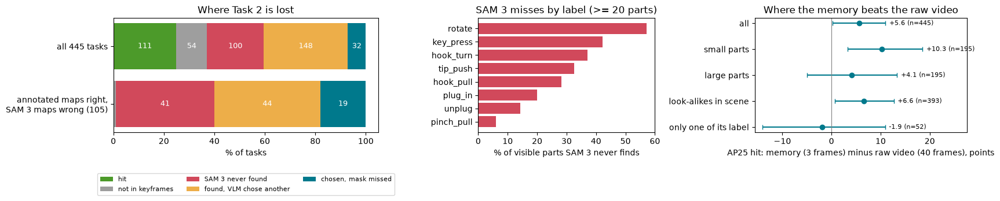

('T2 small', 10.3)

In [9]:
S0 = ROOT / "runs" / "stage0"
t1 = json.loads((S0 / "task2_losses" / "summary.json").read_text())
fig = WR.stage0_losses(t1)
display(fig)
plt.close(fig)
check("T1 hit", t1["stages_memory_arm"]["hit"], 111)
check("T1 lost to annotated", t1["lost_to_annotated"]["tasks"], 105)
check("T1 lost: not chosen", t1["lost_to_annotated"]["stages"]["not_chosen"], 44)
check("T1 lost: never found", t1["lost_to_annotated"]["stages"]["never_found"], 41)
check("T1 lost: mask", t1["lost_to_annotated"]["stages"]["lost_in_mask"], 19)
check("T1 label spread", round(100 * t1["predictions"]["T1-P3"]["spread"]), 51)
check("T2 all", round(t1["memory_minus_raw"]["all"]["diff"], 1), 5.6)
check("T2 small", round(t1["memory_minus_raw"]["small"]["diff"], 1), 10.3)

## 3.3 Part vectors on 30 validation scenes (stage 0, test T3)

**Setup:** the part is given (annotated masks). The scores ask whether the memory's vector gets the motion right:
- **+M:** the type is right;
- **+MA:** the type and the axis or direction are right (within 15°);
- **+MAO:** in addition, the origin is right (within 0.25 m).

The 471 parts are those the keyframes show; 78 more never appear in them.

**Readings:**
- **Main rule:** type from the label plus a gravity axis gives +MA 48.8 and +MAO 38.4.
- **Type given:** the same rule reaches 71.5 and 53.9. The type is the largest error, which is why each part will store
  what it is mounted on.
- **Doors and windows:** the axis direction is right for 82.5% of them, but the hinge position only for 24.5%. That needs
  the door panel (SAM 3 door masks, stage 2).
- **Geometry does not settle the type:** guessing "door or drawer" from geometry is worse than the label alone (+M 68.4
  for the main rule vs 74.3 for label only).

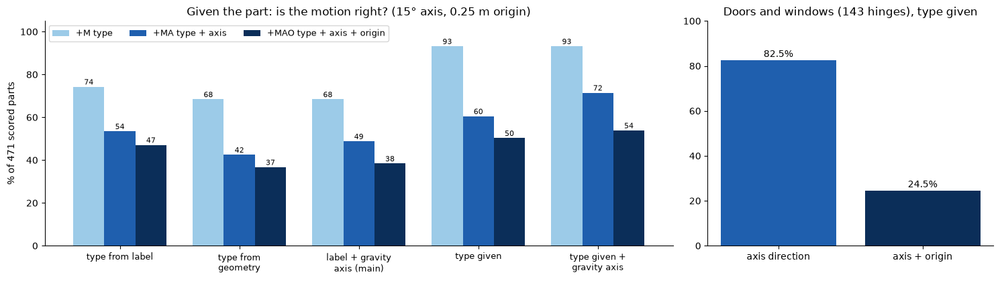

('T3 label-only +M', 74.3)

In [10]:
t3 = H.run_json("t3_val30", "summary.json")
fig = WR.vector_rules(t3)
display(fig)
plt.close(fig)
g, og = t3["variants"]["lidar/gravity/best"], t3["variants"]["lidar/oracle_gravity/best"]
check("T3 scored", t3["counts"]["scored"], 471)
check("T3 not seen", t3["counts"]["not_seen"], 78)
check("T3 gravity +MA", g["all"]["ma"], 48.8)
check("T3 gravity +MAO", g["all"]["mao"], 38.4)
check("T3 type given +MA", og["all"]["ma"], 71.5)
check("T3 type given +MAO", og["all"]["mao"], 53.9)
check("T3 door axis", og["off_part_rotations"]["ma"], 82.5)
check("T3 door origin", og["off_part_rotations"]["mao"], 24.5)
check("T3 gravity +M", g["all"]["m"], 68.4)
check("T3 label-only +M", t3["variants"]["lidar/c1/best"]["all"]["m"], 74.3)

**Why the label alone cannot settle the type.** In the 30 validation scenes, one part label covers parts that slide
and parts that turn. Even choosing each label's majority type gets at most 80.3% of the parts right.

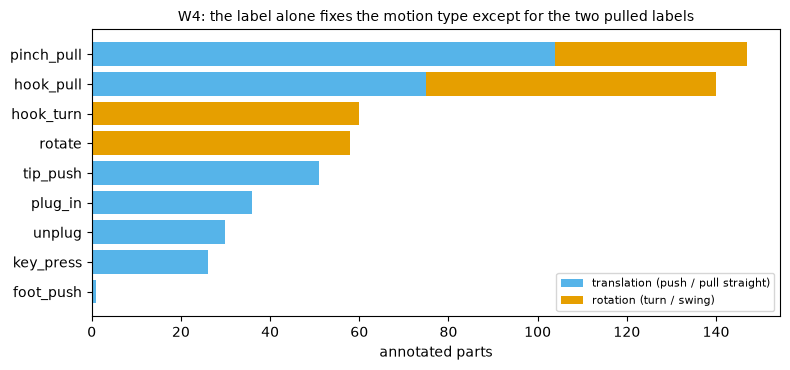

('label-only ceiling %', 80.3)

In [11]:
visits = (ROOT / "third_party" / "scenefun3d" / "benchmark_file_lists" / "val_scenes.txt").read_text().split()
pairs = Counter(pair for visit in visits for pair in CLM.label_motions(ROOT / "data" / "scenefun3d", visit))
fig = H.label_motion_figure(pairs)
display(fig)
plt.close(fig)
best = sum(max(pairs[(lab, "trans")], pairs[(lab, "rot")]) for lab in {lab for lab, _ in pairs})
check("label-only ceiling %", round(100 * best / sum(pairs.values()), 1), 80.3)

**What a robot would do with the memory (demo scene 421069).** Each vector is turned into the path of the contact point:
- slide 30 cm for parts that push or pull;
- turn 60° about the axis for parts that swing;
- turn a full circle for knobs.

Orange follows the memory and green the annotation. Two parts per kind are chosen in advance (those in the most
keyframes), so right and wrong cases both appear.

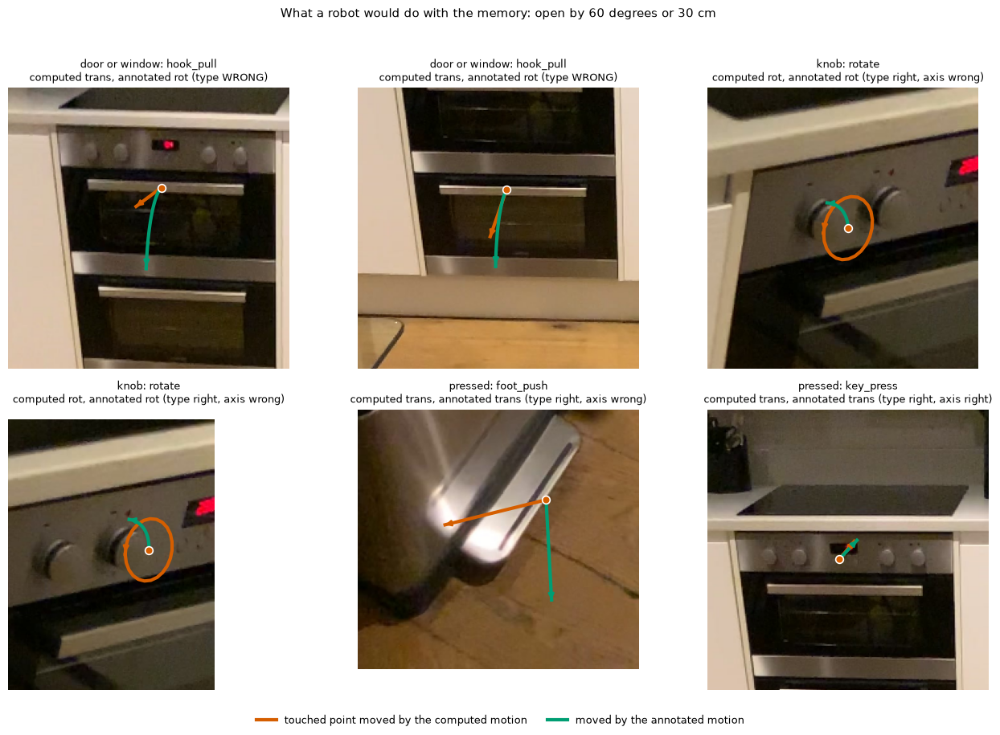

In [12]:
examples = H.pick_examples(demo_rows, truths, DEMO["main"])
fig = H.motion_paths_figure(examples, truths, frames["lidar"])
display(fig)
plt.close(fig)

## 3.4 OpenEQA: does it ask about parts? (stage 0, test T5)

Questions were keyword-flagged, then a hand-read sample of 60 corrected the shares. Only object-state questions ("is the
door open?") often need a part. Over the three focus categories about 15% of questions do, so OpenEQA stays an
auxiliary check for the QA head.

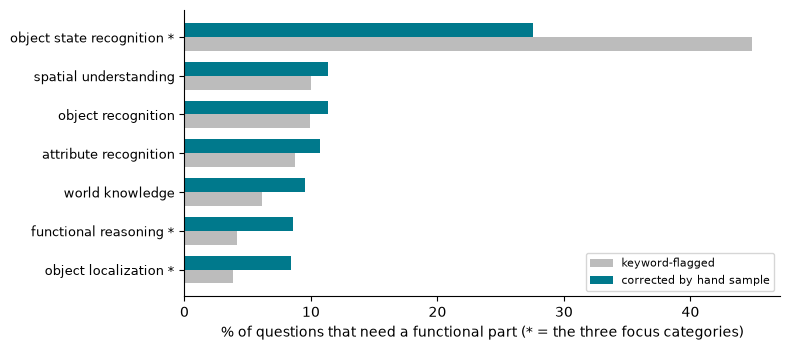

('OpenEQA focus share corrected %', 15.1)

In [13]:
t5 = json.loads((S0 / "openeqa_fit" / "summary.json").read_text())
fig = WR.openeqa_share(t5["table"]["category"], t5["focus_categories"])
display(fig)
plt.close(fig)
check("OpenEQA focus share corrected %", round(100 * t5["focus_corrected_share"], 1), 15.1)

## 3.5 Why "newest overwrites" needs a condition (overwrite simulation)

**Setup:** one video in which nothing changes. How often does SAM 3 find a part that is in view, and how many found
parts would a "one view decides" rule erase?

**Reading:** a part in view is found on a single keyframe only about two times in three. "This frame did not see it"
therefore mostly means a missed detection, not a change. That is why the chosen rule overwrites only where the view is
clear and the geometry has changed.

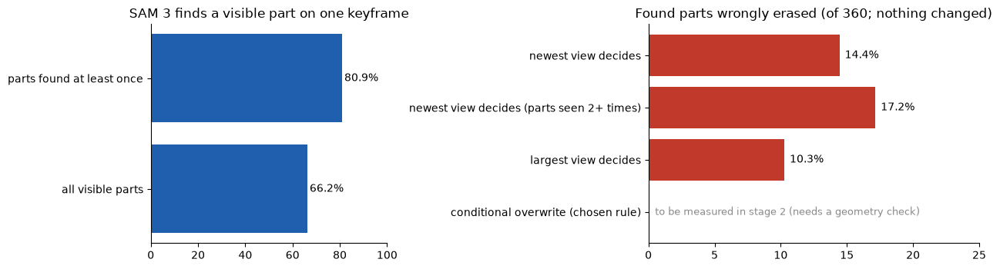

('overwrite largest view erases %', 10.3)

In [14]:
ow = json.loads((S0 / "overwrite_sim" / "summary.json").read_text())
fig = WR.overwrite_bars(ow)
display(fig)
plt.close(fig)
check("overwrite ever found", ow["ever_found"], 360)
check("overwrite per-frame found %", round(100 * ow["per_frame_found_rate"], 1), 66.2)
check("overwrite last view erases %", round(100 * ow["erased"]["last_view"]["all"], 1), 14.4)
check("overwrite last view erases, seen 2+ %", round(100 * ow["erased"]["last_view"]["shown_twice_or_more"], 1), 17.2)
check("overwrite largest view erases %", round(100 * ow["erased"]["largest_view"]["all"], 1), 10.3)

## 3.6 Trial fit of the Gaussian map (stage 1, on GPU 3 as you asked)

**Inputs:** ARKit poses and LiDAR depth, as a robot has them; every 8th frame is held out and scored.

**Validation scene 421254** (below, photo | render | rendered depth): 80 frames.
- It fits in 14.7 min with 3.7 GB peak GPU memory.
- On held-out views the PSNR is 25.4 dB and the median depth error 1.6 cm.
- Three of the four predictions held. The file is 201.5 MB, 1.5 MB over its bound.

**Demo scene 421069:** a large room with sparse frames reaches only 20.3 dB and shows floaters. Rendered close-ups are
therefore reported separately by coverage in stage 2.

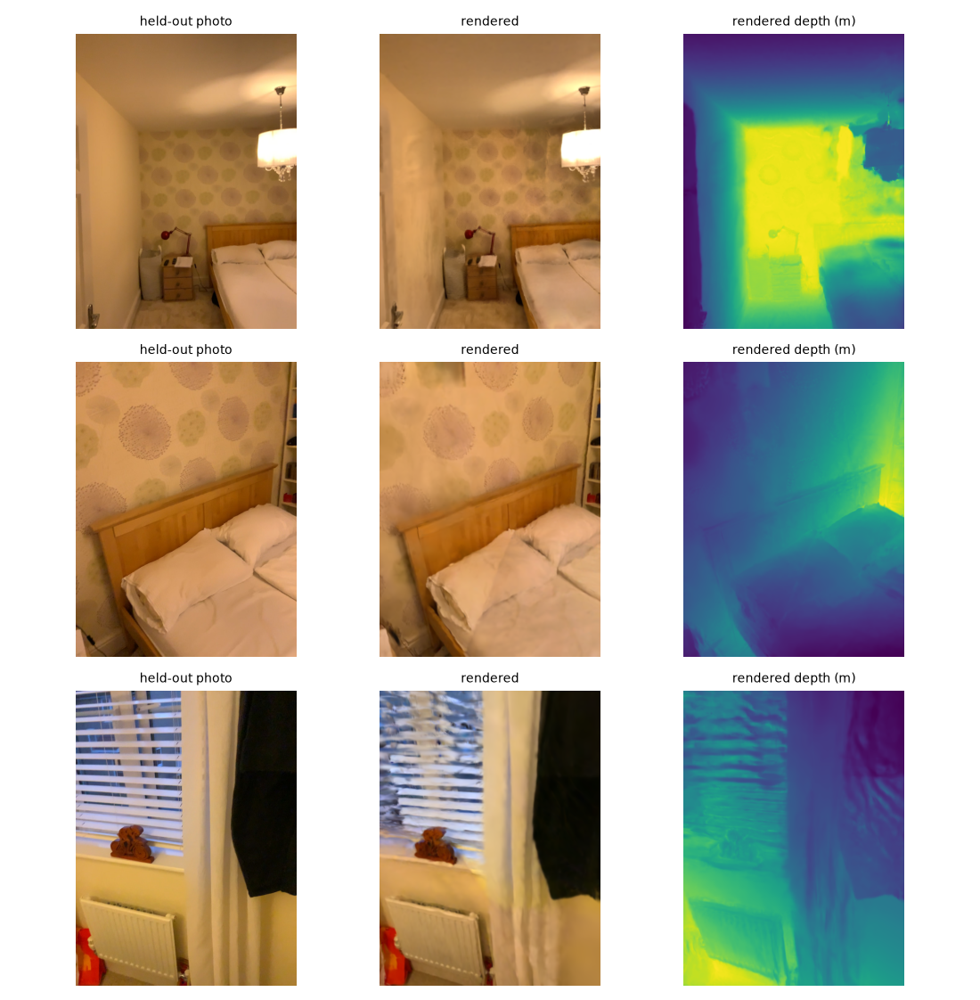

('demo PSNR', 20.3)

In [15]:
fit = json.loads((ROOT / "runs" / "gaussians" / "fit_trial" / "summary.json").read_text())
val, demo = fit["scenes"]
display(Image(filename=str(ROOT / "runs" / "gaussians" / "fit_trial" / f"{val['visit']}_views.png"), width=760))
check("trial fit minutes", round(val["fit_s"] / 60, 1), 14.7)
check("trial peak GPU GB", round(val["peak_gpu_gb"], 1), 3.7)
check("trial frames", val["frames"], 80)
check("trial PSNR", round(val["test_psnr_db"], 1), 25.4)
check("trial depth error cm", round(100 * val["test_depth_median_m"], 1), 1.6)
check("trial file MB", round(val["file_mb"], 1), 201.5)
check("demo PSNR", round(demo["test_psnr_db"], 1), 20.3)

---
# 4. Memory form: one Gaussian map per room

**What others store:**
- **Text graphs:** an LLM reads captions. A wrong caption, or a part never detected, cannot be recovered, because the
  pixels are gone. On OpenEQA, GPT-4 reading ConceptGraphs captions scores 36.5, close to a blind LLM at 33.5, while
  GPT-4V reading frames scores 55.3.
- **Image memories:** these re-read stored views and lose small parts at their stored resolution.
- **SceneFun3D methods:** these re-read the whole video for every question.
- **Dense feature maps:** these mostly stay at object level, and rarely update across visits.

**The gap:** no published system keeps one training-free, room-scale map that a new video is relocalised into, that is
updated locally below object level, and that stores how each part moves.

The detailed tables, checked against arXiv, are in the proposal document, sections 15–16.

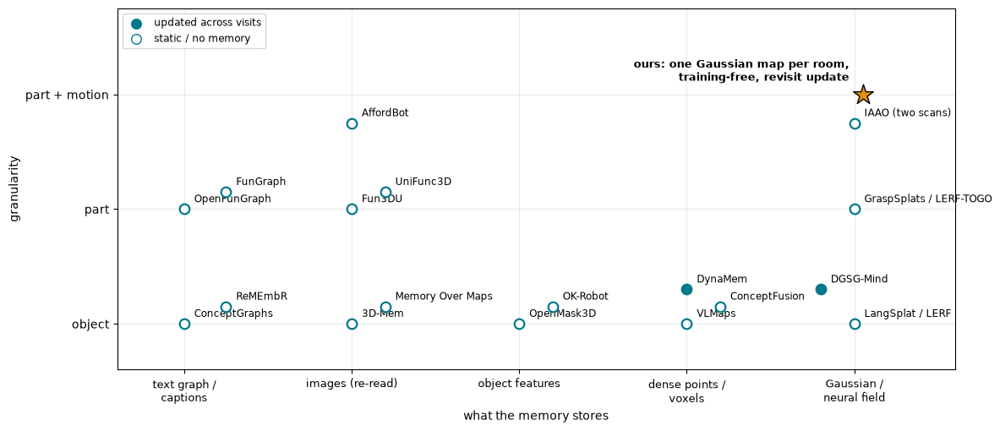

In [16]:
fig = WR.positioning()
display(fig)
plt.close(fig)

---
# 5. Stage 2: run end to end (started 20 Nov)

**Data:** the 30 validation scenes have 82 videos, the phase-1 video of each scene plus 52 second visits (keyframes only,
3.1 GB).

**GPU jobs:** queued in front of your own jobs, on the default cards 0 1 4 5 6 7.
- **SAM 3 part maps** of the 52 second-visit videos.
- **Gaussian maps** of all 82 videos, with the trial's settings.
  - On the first pass, 64 were fitted and 18 failed with CUDA out-of-memory. Our jobs used 3–4 GB, but other users'
    processes of about 17 GB each filled the shared cards.
  - That breaks the prediction "at most 4 failures" (G2-P4) on the first pass. The 18 were re-queued with the same
    settings, waiting for 12 GB of free memory before starting.
  - The cell below shows the state at build time.

**At build time:** SAM 3 maps of second-visit videos finished: **52 of 52**. Gaussian maps: **65 fitted**, **17 failed so far and re-queued**, 0 not reached yet (of 82).

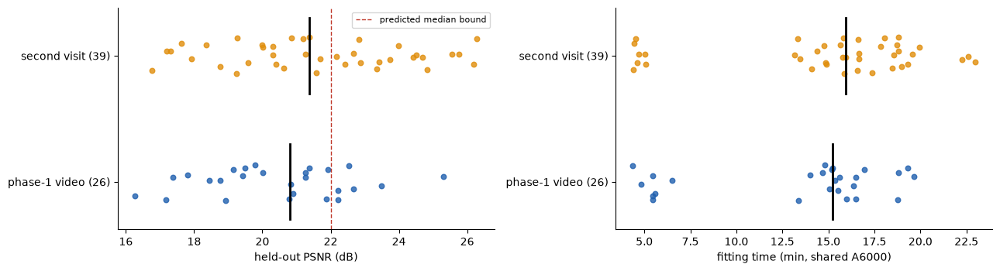

prediction (over the videos fitted so far),value,
G2-P1 median fit minutes,15.700000,held
G2-P2 median held-out PSNR,21.190000,not held
G2-P3 median depth error m,0.022000,held
G2-P4 videos fitted,65 of 82,not held


('revisit videos listed', 52)

In [17]:
spec = importlib.util.spec_from_file_location("fit_gaussians_batch", ROOT / "scripts" / "fit_gaussians_batch.py")
FGB = importlib.util.module_from_spec(spec)
spec.loader.exec_module(FGB)
CFG = load_config(ROOT / "configs" / "gaussians" / "fit_val82.yaml")
OUT = ROOT / CFG["outputs"] / CFG["name"]
stems = [f"{v['visit']}_{v['video']}" for v in FGB.videos(CFG)]
rows = [json.loads((OUT / f"{s}.json").read_text()) for s in stems if (OUT / f"{s}.json").exists()]
failed = [s for s in stems if (OUT / f"{s}.failed.json").exists() and not (OUT / f"{s}.json").exists()]
sam3 = sorted((ROOT / "runs" / "stage2" / "tool_maps" / "sam3").glob("*_*.json"))
sam3_done = sum(len(json.loads(p.read_text())["keyframes"]) == 40 for p in sam3)
display(Markdown(f"**At build time:** SAM 3 maps of second-visit videos finished: **{sam3_done} of 52**. "
                 f"Gaussian maps: **{len(rows)} fitted**, **{len(failed)} failed so far and re-queued**, "
                 f"{len(stems) - len(rows) - len(failed)} not reached yet (of {len(stems)})."))
fig = WR.stage2_fits(rows)
display(fig)
plt.close(fig)
pred = FGB.judge(rows, len(stems) - len(rows), CFG["expect"]) if rows else {}
display(pd.DataFrame([[k, v["value"], "held" if v["held"] else "not held"] for k, v in pred.items()],
                     columns=["prediction (over the videos fitted so far)", "value", ""]).style.hide(axis="index"))
check("revisit videos listed", len(stems) - 30, 52)

**Next in stage 2** (each comparison is written down with its predictions before it runs):
1. **"Mounted on what?" (W4):** the VLM prompt and its scoring, shown to you before it runs.
2. **Lifting features onto the Gaussians:** training-free, in the style of Occam's LGS or LUDVIG. The voxel control uses
   the same five operations.
3. **Second visit:** relocalisation with AnyLoc and Reloc3r, then the conditional overwrite, checked by rendering and by
   depth.
4. **Task 3 scorer:** our own, following the public definitions, plus one run under AffordBot's protocol.
5. **Comparisons:**
   - retrieval of the target part, including the 41 parts SAM 3 never found;
   - VLM picks on rendered close-ups vs the best keyframes, on the 44 "chose another part" tasks;
   - update errors on the second visit;
   - cost.

---
# 6. Main-idea check

| Main idea | This week | Verdict |
| --- | --- | --- |
| M1 interpretable 3D vector, robot-ready | part vectors in world coordinates; tested on 30 scenes | conforms |
| M2 the vector helps choose keyframes | each map element records the frames that saw it; close-ups rendered on demand | conforms |
| M3 affordance + depth → action vector | rules on LiDAR depth; the type comes from "mounted on" (stage 2) | conforms |
| M4 two heads (open QA, action vector) | action head built; QA head interface frozen, not built | partly |
| M5 off-the-shelf models + rules, no training | no network trained; per-scene Gaussian fitting counts as reconstruction (your 20 Nov ruling) | conforms |
| M6 minimal resources | stage 0 CPU only; about 15 GPU-min and 0.2 GB per video for a map | conforms |

No drift this week.

## ✏️ Your notes

Write comments and updates for this week here; I read them and answer point by point.

(empty)

---
# Appendix

## A. Commands (repository root, on the server; GPU steps only through the queue)

| What | Command |
| --- | --- |
| Part vectors (S0, S0b, S0c, demo, T3) | `python scripts/run_part_vectors.py --config configs/part_vectors/<s0_421069 / s0b_val3 / s0c_gravity_val3 / demo_421069_gravity / t3_val30>.yaml` |
| Public evaluation, Task 2 | `python scripts/run_public_eval.py --config configs/public_eval/split0_8b.yaml --stage <queue / lift / score --official>` |
| Stage 0: Task 2 losses, OpenEQA | `python scripts/diagnose_task2_losses.py --config configs/stage0/task2_losses.yaml`; `python scripts/openeqa_fit.py --config configs/stage0/openeqa_fit.yaml --stage <count / correct>` |
| Overwrite simulation | `python scripts/simulate_overwrite.py --config configs/stage0/overwrite_sim.yaml` |
| Label vs motion type | `python scripts/count_label_motions.py --scenes third_party/scenefun3d/benchmark_file_lists/val_scenes.txt` |
| Gaussian trial (GPU queue) | `bash scripts/remote/setup_gaussians.sh` once; `bash scripts/remote/queue_fit_gaussians.sh configs/gaussians/fit_trial.yaml 100 11000 3` |
| Stage 2: second-visit videos | `python scripts/download_revisit_videos.py --scenes third_party/scenefun3d/benchmark_file_lists/val_scenes.txt` |
| Stage 2: SAM 3, Gaussian maps (GPU queue) | `bash scripts/remote/queue_tool_maps_revisit.sh configs/stage2/revisit_videos.txt 2`; `bash scripts/remote/queue_fit_gaussians_batch.sh configs/gaussians/fit_val82.yaml 6`, then `python scripts/fit_gaussians_batch.py --config configs/gaussians/fit_val82.yaml --stage summarise` |
| Videos; interactive 3D file | `python scripts/make_week2_media.py --config configs/report/week2_media.yaml`; `python scripts/make_week2_rrd.py --config configs/report/week2_rrd.yaml` |
| This notebook | `python notebooks/builders/build_report_2026_11_20_week2.py report/week2_2026-11-16_to_11-22.ipynb`, then `jupyter nbconvert --to notebook --execute --inplace` |

**Documents:** the proposal and every discussion of the week (Chinese): `docs/mem/新pipeline_差异_文献_推荐_2026-11-18.md`;
understanding gaps: `docs/mem/理解差异记录.md`; experiment index: `EXPERIMENTS.md`. The earlier, longer Chinese version of
this notebook is in git history (commit b5b1267).

## B. Number checks

Each number quoted in the text was recomputed from the result files in the cell that shows it; a mismatch stops the
notebook.

In [18]:
print(f"{len(CHECKS)} numbers checked, all match the result files:")
print("; ".join(CHECKS))

49 numbers checked, all match the result files:
S0c door axis right, type given %; S0c door axis right, gravity axis %; walkthrough frames; tap axis error, degrees (smaller of the two); knobs without a task; knob axes within 15 degrees; rrd parts; rrd size MB; raw video AP25; memory SAM 3 AP25; memory annotated AP25; UniFunc3D 8B AP25; memory minus UniFunc3D AP25; memory minus raw video AP25; oracle_chosen AP25; oracle_best AP25; T1 hit; T1 lost to annotated; T1 lost: not chosen; T1 lost: never found; T1 lost: mask; T1 label spread; T2 all; T2 small; T3 scored; T3 not seen; T3 gravity +MA; T3 gravity +MAO; T3 type given +MA; T3 type given +MAO; T3 door axis; T3 door origin; T3 gravity +M; T3 label-only +M; label-only ceiling %; OpenEQA focus share corrected %; overwrite ever found; overwrite per-frame found %; overwrite last view erases %; overwrite last view erases, seen 2+ %; overwrite largest view erases %; trial fit minutes; trial peak GPU GB; trial frames; trial PSNR; trial depth 